# 6. Adaptive Step Size

A fixed step size $h$ is a compromise. It wastes effort where the solution is smooth, and is too coarse where the solution changes quickly. **Adaptive** solvers estimate the error of every step as they go and choose $h$ to keep that error close to a tolerance set by the user. This section shows how the error is estimated, how the next step size is chosen, and builds two adaptive solvers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

def heun(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h, y[i] + h * k1)
        y[i + 1] = y[i] + h / 2 * (k1 + k2)
        x[i + 1] = x[i] + h
    return x, y

def rk4(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(x[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        x[i + 1] = x[i] + h
    return x, y

## 6.1 Estimating the local error

An adaptive solver needs, after each step, an estimate of the **local** error of that step. There are two standard ways to get one.

**Step doubling.** Take one step of size $h$ and, separately, two steps of size $h/2$ with the same method of order $p$. By the Richardson argument of [Section 4.4](04-error-order-efficiency.ipynb), the difference divided by $2^p - 1$ estimates the error. It works with any method, but it roughly triples the cost of every step.

**Embedded pairs.** Use two Runge–Kutta methods, of orders $q$ and $q + 1$, that **share the same stages** $k_i$ and differ only in the final weights $\mathbf{b}$ and $\hat{\mathbf{b}}$. Both results come almost for free from the same slopes, and

$$\text{err} = \big|\,y^{(q+1)}_{n+1} - y^{(q)}_{n+1}\big| = h\,\Big|\sum_i (b_i - \hat b_i)\,k_i\Big|$$

estimates the local error of the **lower-order** result, because the higher-order one is much more accurate. All modern explicit adaptive solvers use embedded pairs.

## 6.2 Choosing the next step size

The local error of the order-$q$ method behaves like $\text{err} \approx C\,h^{q+1}$. If the step just taken had error $\text{err}$, the step that would have produced exactly the tolerance $\text{tol}$ satisfies $C\,h_{\text{new}}^{q+1} = \text{tol}$. Dividing the two relations eliminates the unknown $C$:

$$h_{\text{new}} = h\left(\frac{\text{tol}}{\text{err}}\right)^{1/(q+1)}.$$

Practical solvers add three safeguards:

1. A **safety factor** (about $0.9$) so that the next step is likely to be accepted.
2. **Limits** on how fast $h$ may change (for example, at most $\times 5$ and at least $\times 0.2$ per step), because the asymptotic error model can be wrong.
3. A **mixed tolerance** $\text{tol} = \text{atol} + \text{rtol}\,|y|$: an absolute tolerance for small $y$ and a relative one for large $y$.

**The algorithm.**
1. Take a step of size $h$ and compute $\text{err}$.
2. If $\text{err} \le \text{tol}$, **accept** the step and move on. Otherwise **reject** it and stay at $x_n$.
3. In either case, compute $h_{\text{new}}$ and use it for the next attempt.

Although the error estimate is for the lower-order result, solvers usually continue with the **higher-order** result. This is called **local extrapolation**: the actual error is then even smaller than the estimate.

## 6.3 The Heun–Euler pair

The simplest embedded pair is Euler (order 1) and Heun (order 2). They share $k_1$:

$$
y^{\text{E}}_{n+1} = y_n + hk_1, \qquad y^{\text{H}}_{n+1} = y_n + \tfrac{h}{2}(k_1 + k_2), \qquad \text{err} = \big|y^{\text{H}}_{n+1} - y^{\text{E}}_{n+1}\big| = \tfrac{h}{2}\,|k_2 - k_1|.
$$

The lower order is $q = 1$, so $h_{\text{new}} = 0.9\,h\sqrt{\text{tol}/\text{err}}$.

**Example.** $y' = 1 + y^2$, $y(0) = 0$, with exact solution $y = \tan x$, which becomes very steep near $x = \pi/2 \approx 1.571$. We integrate to $x = 1.5$.

accepted steps: 89,  rejected: 3
exact tan(1.5) = 14.10142
adaptive Heun:              y(1.5) = 14.09386   error = 0.0076
fixed-step Heun, 89 steps: y(1.5) = 13.81361   error = 0.2878


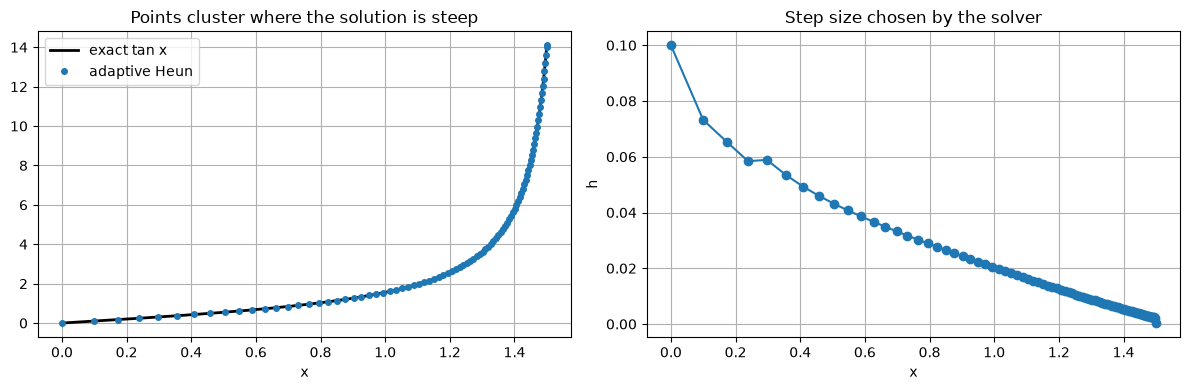

In [2]:
def adaptive_heun(f, x0, y0, x_end, tol=1e-3, h=0.1):
    xs, ys = [x0], [y0]
    x, y = x0, y0
    rejected = 0
    while x_end - x > 1e-12:
        h = min(h, x_end - x)
        k1 = f(x, y)
        k2 = f(x + h, y + h * k1)
        err = h / 2 * abs(k2 - k1)
        allowed = tol * (1 + abs(y))
        if err <= allowed:
            x, y = x + h, y + h / 2 * (k1 + k2)
            xs.append(x); ys.append(y)
        else:
            rejected += 1
        h *= min(2.0, max(0.2, 0.9 * np.sqrt(allowed / err))) if err > 0 else 2.0
    return np.array(xs), np.array(ys), rejected

tanf = lambda x, y: 1 + y**2
xa, ya, rej = adaptive_heun(tanf, 0.0, 0.0, 1.5)
print(f"accepted steps: {len(xa) - 1},  rejected: {rej}")
print(f"exact tan(1.5) = {np.tan(1.5):.5f}")
print(f"adaptive Heun:              y(1.5) = {ya[-1]:.5f}   error = {abs(ya[-1] - np.tan(1.5)):.4f}")

n_fixed = len(xa) - 1
xh, yh_fixed = heun(tanf, 0, 0, 1.5 / n_fixed, n_fixed)
print(f"fixed-step Heun, {n_fixed} steps: y(1.5) = {yh_fixed[-1]:.5f}   error = {abs(yh_fixed[-1] - np.tan(1.5)):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xf = np.linspace(0, 1.5, 300)
axes[0].plot(xf, np.tan(xf), "k", lw=2, label="exact tan x")
axes[0].plot(xa, ya, "o", ms=4, label="adaptive Heun")
axes[0].set_title("Points cluster where the solution is steep")
axes[0].set_xlabel("x"); axes[0].legend()
axes[1].plot(xa[:-1], np.diff(xa), "o-")
axes[1].set_title("Step size chosen by the solver")
axes[1].set_xlabel("x"); axes[1].set_ylabel("h")
plt.tight_layout()

With the same number of steps, the adaptive solver is about 40 times more accurate than fixed steps. It takes large steps where $\tan x$ is flat and puts its effort near $x = 1.5$, where the solution is steep.

## 6.4 A better pair: Bogacki–Shampine 3(2)

The **Bogacki–Shampine** pair combines a third-order and a second-order method. It is the method behind MATLAB's `ode23` and SciPy's `solve_ivp(method="RK23")`.

$$
\begin{array}{c|cccc}
0 & & & & \\
\tfrac12 & \tfrac12 & & & \\
\tfrac34 & 0 & \tfrac34 & & \\
1 & \tfrac29 & \tfrac13 & \tfrac49 & \\ \hline
\text{order 3:}\ \mathbf b & \tfrac29 & \tfrac13 & \tfrac49 & 0 \\
\text{order 2:}\ \hat{\mathbf b} & \tfrac{7}{24} & \tfrac14 & \tfrac13 & \tfrac18
\end{array}
$$

**First same as last (FSAL).** The fourth stage is evaluated at $\big(x_n + h,\ y_n + h(\tfrac29k_1 + \tfrac13k_2 + \tfrac49k_3)\big)$, which is exactly the new point $(x_{n+1}, y_{n+1})$. So $k_4$ of this step is $k_1$ of the next step, and each accepted step costs only **three** new evaluations of $f$ even though the method has four stages.

The lower order is $q = 2$, so the step-size update uses the exponent $1/3$.

In [3]:
def bs32(f, x0, y0, x_end, rtol=1e-6, atol=1e-6, h=None):
    """Bogacki–Shampine 3(2) with FSAL and local extrapolation."""
    x, y = x0, y0
    xs, ys = [x], [y]
    k1 = f(x, y); nfev = 1
    if h is None:
        h = 0.01 * (x_end - x0)
    rejected = 0
    while x_end - x > 1e-12 * max(1, abs(x_end)):
        h = min(h, x_end - x)
        k2 = f(x + h / 2, y + h / 2 * k1)
        k3 = f(x + 3 * h / 4, y + 3 * h / 4 * k2)
        y_new = y + h * (2 / 9 * k1 + 1 / 3 * k2 + 4 / 9 * k3)
        k4 = f(x + h, y_new)
        nfev += 3
        y_low = y + h * (7 / 24 * k1 + 1 / 4 * k2 + 1 / 3 * k3 + 1 / 8 * k4)
        err = abs(y_new - y_low)
        tol = atol + rtol * max(abs(y), abs(y_new))
        if err <= tol:
            x, y, k1 = x + h, y_new, k4          # FSAL: k4 becomes the next k1
            xs.append(x); ys.append(y)
        else:
            rejected += 1
        h *= min(5.0, max(0.2, 0.9 * (tol / err) ** (1 / 3))) if err > 0 else 5.0
    return np.array(xs), np.array(ys), nfev, rejected

xb, yb, nfev, rej = bs32(tanf, 0.0, 0.0, 1.5, rtol=1e-6, atol=1e-6)
print(f"BS32, tol 1e-6: {len(xb) - 1} accepted steps, {rej} rejected, {nfev} f evaluations, "
      f"error at 1.5 = {abs(yb[-1] - np.tan(1.5)):.2e}")

BS32, tol 1e-6: 157 accepted steps, 0 rejected, 472 f evaluations, error at 1.5 = 3.80e-04


## 6.5 What the tolerance buys

The tolerance controls the **local** error of each step. The quantity the user cares about is the **global** error at the end, which accumulates all the local errors (and their amplification, see [Section 1.5](01-eulers-method.ipynb)). So the global error is not guaranteed to be below the tolerance, but it should fall in proportion as the tolerance is tightened.

The table runs BS32 on the $\tan x$ problem for a range of tolerances. The plot compares its error against the number of $f$ evaluations with fixed-step RK4.

     tol  steps  rejected  f evals  error at 1.5
   1e-02     10         6       49      1.38e+00
   1e-03     18        14       97      2.56e-01
   1e-04     34        10      133      3.68e-02
   1e-05     72         0      217      3.95e-03
   1e-06    157         0      472      3.80e-04
   1e-07    340         1     1024      3.73e-05
   1e-08    736         1     2212      3.70e-06


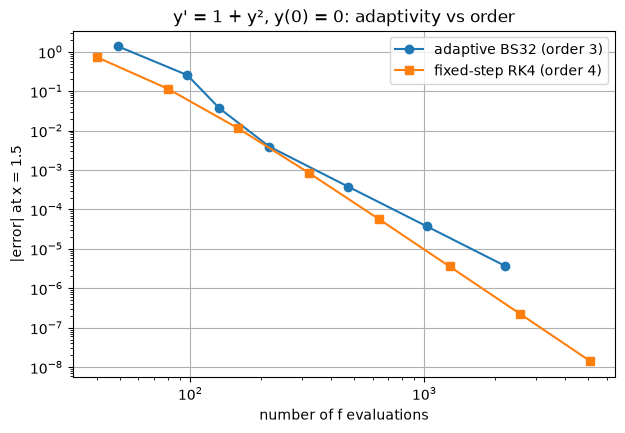

In [4]:
print(f"{'tol':>8} {'steps':>6} {'rejected':>9} {'f evals':>8} {'error at 1.5':>13}")
adapt = []
for tol in [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]:
    xb, yb, nfev, rej = bs32(tanf, 0.0, 0.0, 1.5, rtol=tol, atol=tol)
    err = abs(yb[-1] - np.tan(1.5))
    adapt.append((nfev, err))
    print(f"{tol:8.0e} {len(xb) - 1:6d} {rej:9d} {nfev:8d} {err:13.2e}")

fixed = []
for n in [10, 20, 40, 80, 160, 320, 640, 1280]:
    _, y = rk4(tanf, 0, 0, 1.5 / n, n)
    fixed.append((4 * n, abs(y[-1] - np.tan(1.5))))

plt.loglog(*zip(*adapt), "o-", label="adaptive BS32 (order 3)")
plt.loglog(*zip(*fixed), "s-", label="fixed-step RK4 (order 4)")
plt.xlabel("number of f evaluations"); plt.ylabel("|error| at x = 1.5")
plt.title("y' = 1 + y², y(0) = 0: adaptivity vs order"); plt.legend();

Two things stand out.

* **The global error is much larger than the tolerance**, here a few hundred times larger, but it falls in proportion as the tolerance is tightened (from $10^{-5}$ on, about ten times smaller error per factor of ten in tolerance). The amplification comes from $\partial f/\partial y = 2y$, which becomes large near $x = 1.5$, so local errors made earlier grow (the factor $e^{L(x - x_0)}$ of [Section 1.5](01-eulers-method.ipynb)). To get a guaranteed final accuracy, tighten the tolerance until the answer stops changing.
* **Fixed-step RK4 is competitive here.** Its higher order (4 against 3) outweighs the benefit of adaptivity for a third-order method on this interval. The fair comparison is with an adaptive method of the *same* order. Adaptivity also has an advantage that does not show in the plot: you state the accuracy you want instead of guessing a step size, and the solver also copes with problems where a fixed step would fail.

Production solvers therefore combine both ideas, using higher-order embedded pairs such as Dormand–Prince 5(4) (`ode45`, `solve_ivp(method="RK45")`) or Tsitouras 5(4) (`Tsit5` in Julia).

## 6.6 Adaptive solvers reveal stiffness

What happens when an adaptive explicit solver meets a stiff problem? Take the example of [Section 5.5](05-stability-and-stiffness.ipynb),

$$y' = -50\,(y - \cos x), \qquad y(0) = 0, \qquad 0 \le x \le 10.$$

After the brief transient the solution is as smooth as $\cos x$, and a loose tolerance should allow large steps. But the propagated BS32 solution is third order with three stages, so its stability function is $1 + z + z^2/2 + z^3/6$, which is stable on the real axis only for $h|\lambda| \le 2.51$. Here $\lambda = -50$, so $h \le 0.05$.

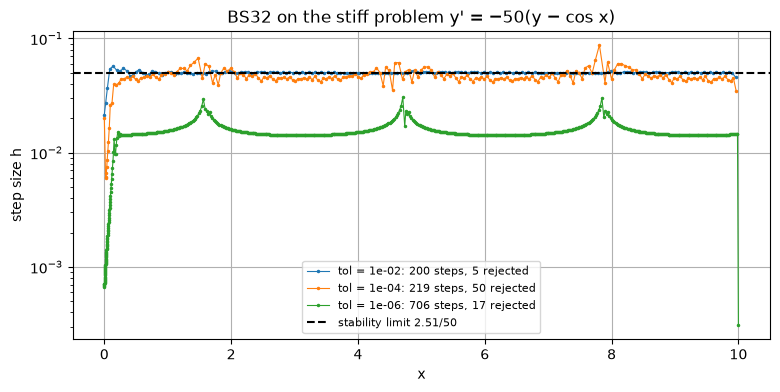

In [5]:
stiff = lambda x, y: -50 * (y - np.cos(x))
fig, ax = plt.subplots(figsize=(9, 4))
for tol in [1e-2, 1e-4, 1e-6]:
    xb, yb, nfev, rej = bs32(stiff, 0.0, 0.0, 10.0, rtol=tol, atol=tol)
    ax.semilogy(xb[:-1], np.diff(xb), ".-", ms=3, lw=0.8, label=f"tol = {tol:.0e}: {len(xb)-1} steps, {rej} rejected")
ax.axhline(2.5127 / 50, color="k", ls="--", label="stability limit 2.51/50")
ax.set_xlabel("x"); ax.set_ylabel("step size h")
ax.set_title("BS32 on the stiff problem y' = −50(y − cos x)")
ax.legend(fontsize=8);

With the looser tolerances, the step size climbs after the transient and then **stalls at the stability limit**, no matter how loose the tolerance is. The solver repeatedly tries a larger step, the error estimate grows (because the step is unstable), the step is rejected or shrunk, and the cycle repeats. Only the tightest tolerance keeps the step below the limit for accuracy reasons.

A step size that stays pinned at the same value regardless of the tolerance, often with many rejected steps, is the classic **symptom of stiffness**. The cure is an implicit method; some solvers (such as `LSODA`, or `AutoTsit5(Rosenbrock23())` in Julia) detect this automatically and switch.

## 6.7 Choosing a method in practice

| Situation | Good choice |
|---|---|
| Learning, or a quick rough look | Euler, with a check by halving $h$ |
| Smooth, non-stiff problem | Adaptive RK45 (`ode45`, `RK45`, `Tsit5`); fixed-step RK4 if the step is easy to choose |
| Solution changes scale a lot | Adaptive step size |
| Stiff problem (fast and slow scales) | Implicit method: BDF, Radau, Rosenbrock (`ode15s`, `BDF`, `Rodas5`) |
| Very long integrations of conservative systems | Symplectic methods ([Section 8](08-systems-and-higher-order.ipynb)) |

### Common pitfalls

* **Step too large:** inaccurate, or unstable ([Section 5](05-stability-and-stiffness.ipynb)).
* **Step too small:** wasted work, and eventually **round-off error** grows ([Section 4.6](04-error-order-efficiency.ipynb)).
* **No convergence check:** a single run tells you nothing about its accuracy. Halve $h$, or tighten the tolerance, and compare.
* **Tolerance is not accuracy:** the tolerance bounds local errors; the global error can be larger, especially over long intervals.
* **Singularities and blow-up:** if the true solution becomes infinite, as $\tan x$ does at $\pi/2$, no method can step past it; adaptive solvers will shrink $h$ towards zero.
* **Order assumes smoothness:** if $f$ has a jump or a kink, the observed order drops. Place a grid point at the discontinuity, or restart the solver there.

## Exercises

1. Show that for the Heun–Euler pair, $y^{\text{H}}_{n+1} - y^{\text{E}}_{n+1} = \frac{h}{2}(k_2 - k_1)$.
2. A step of a 3(2) pair with $h = 0.1$ gives $\text{err} = 4 \times 10^{-5}$ with $\text{tol} = 10^{-6}$. Is it accepted? What step does the controller try next (safety factor 0.9)?
3. Run `bs32` on $y' = -2xy$, $y(0) = 1$ over $[0, 3]$ with tolerance $10^{-6}$ and plot the step sizes. Where are the steps smallest, and why?
4. Why do adaptive solvers report the number of $f$ evaluations rather than the number of steps?

**Answers**

1. $y_n + \tfrac{h}{2}(k_1 + k_2) - (y_n + hk_1) = \tfrac{h}{2}(k_2 - k_1)$.
2. Rejected, since $4 \times 10^{-5} > 10^{-6}$. Next try: $0.9 \times 0.1 \times (10^{-6}/4\times10^{-5})^{1/3} = 0.09 \times 0.292 \approx 0.026$.
3. See the cell below. The local error estimate is roughly proportional to $h^3 y^{\prime\prime\prime}$. For $y = e^{-x^2}$, $y^{\prime\prime\prime} = (12x - 8x^3)e^{-x^2}$, which is largest in size at $x \approx 0.53$ and $x \approx 1.65$ and zero at $x = \sqrt{1.5} \approx 1.22$. The steps are smallest near the first two points, briefly jump up near $x \approx 1.22$, and grow steadily as the solution flattens out beyond $x \approx 2$.
4. The cost of a step depends on the method (3 evaluations for BS32 with FSAL, 6 for Dormand–Prince with FSAL) and rejected steps cost evaluations too. The number of evaluations measures the actual work.

2.  next h = 0.0263
3.  79 steps, 5 rejected, max error 9.8e-06


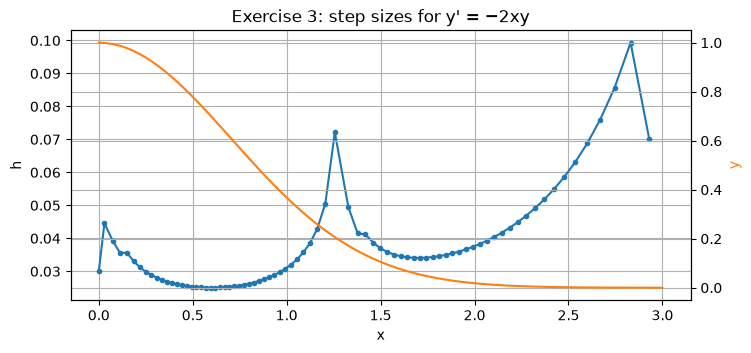

In [6]:
print(f"2.  next h = {0.9 * 0.1 * (1e-6 / 4e-5) ** (1 / 3):.4f}")
g = lambda x, y: -2 * x * y
xb, yb, nfev, rej = bs32(g, 0.0, 1.0, 3.0, rtol=1e-6, atol=1e-6)
print(f"3.  {len(xb) - 1} steps, {rej} rejected, max error {np.max(np.abs(yb - np.exp(-xb**2))):.1e}")
fig, ax1 = plt.subplots(figsize=(8, 3.5))
ax1.plot(xb[:-1], np.diff(xb), "o-", ms=3, label="step size")
ax1.set_xlabel("x"); ax1.set_ylabel("h")
ax2 = ax1.twinx()
ax2.plot(xb, yb, "C1", label="y = e^(−x²)"); ax2.set_ylabel("y", color="C1")
ax1.set_title("Exercise 3: step sizes for y' = −2xy");